In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import skew
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

df = pd.read_csv('hf://datasets/maharshipandya/spotify-tracks-dataset/dataset.csv')
print(df.shape)

(114000, 21)


In [ ]:
feats = ['danceability','energy','loudness','speechiness','acousticness',
         'instrumentalness','liveness','valence','tempo']
genres = ['classical','hip-hop','mandopop','metal']

d = df[df.track_genre.isin(genres)]
d = d.drop_duplicates('track_id')
d = d.drop_duplicates(subset=feats)
d = d.reset_index(drop=True)
print(len(d))
print(d.track_genre.value_counts())

3408
track_genre
mandopop     985
metal        862
classical    814
hip-hop      747
Name: count, dtype: int64


speechiness         3.04
liveness            2.30
instrumentalness    1.71
loudness           -1.65
valence             0.39
acousticness        0.34
energy             -0.31
tempo               0.27
danceability       -0.00
dtype: float64


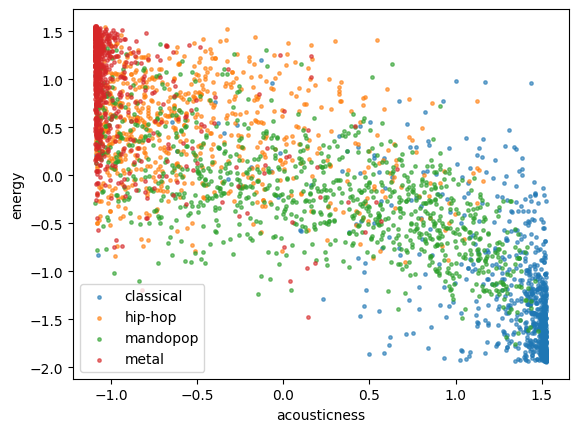

In [ ]:
X = d[feats].to_numpy(float)
Z = (X - X.mean(0)) / X.std(0, ddof=0)

sk = pd.Series(skew(Z, axis=0), index=feats).round(2)
print(sk.sort_values(key=abs, ascending=False))

ai, ei = feats.index('acousticness'), feats.index('energy')
for g in genres:
    m = (d.track_genre == g).to_numpy()
    plt.scatter(Z[m, ai], Z[m, ei], s=6, label=g, alpha=.6)
plt.xlabel('acousticness'); plt.ylabel('energy'); plt.legend()

In [ ]:
def sqdist(X, C):
    d2 = (X**2).sum(1)[:,None] + (C**2).sum(1)[None,:] - 2*X@C.T
    return np.maximum(d2, 0)

def kmeans(X, C0, max_iter=20):
    C = C0.copy().astype(float)
    k = len(C)
    hist = [sqdist(X, C).min(1).sum()]
    for t in range(max_iter):
        labels = sqdist(X, C).argmin(1)
        for j in range(k):
            m = labels == j
            if m.any():
                C[j] = X[m].mean(0)
        hist.append(sqdist(X, C).min(1).sum())
    labels = sqdist(X, C).argmin(1)
    return labels, C, np.array(hist)

In [ ]:
C0 = Z[np.random.default_rng(0).choice(len(Z), 4, replace=False)]
lab, C, h = kmeans(Z, C0, max_iter=300)
km = KMeans(n_clusters=4, init=C0, n_init=1, max_iter=300, tol=0).fit(Z)
print(h[-1], km.inertia_)

15824.802731134696 15824.802731134676


In [ ]:
def init_random(Z, k, seed):
    rng = np.random.default_rng(seed)
    return Z[rng.choice(len(Z), k, replace=False)]

def init_ff(Z, k, seed, return_idx=False):
    rng = np.random.default_rng(seed)
    idx = [rng.integers(len(Z))]
    dmin = sqdist(Z, Z[idx]).ravel()
    for _ in range(k-1):
        j = int(dmin.argmax()); idx.append(j)
        dmin = np.minimum(dmin, sqdist(Z, Z[[j]]).ravel())
    return (Z[idx], idx) if return_idx else Z[idx]

def init_pp(Z, k, seed):
    rng = np.random.default_rng(seed)
    idx = [rng.integers(len(Z))]
    dmin = sqdist(Z, Z[idx]).ravel()
    for _ in range(k-1):
        j = rng.choice(len(Z), p=dmin/dmin.sum())
        idx.append(j)
        dmin = np.minimum(dmin, sqdist(Z, Z[[j]]).ravel())
    return Z[idx]

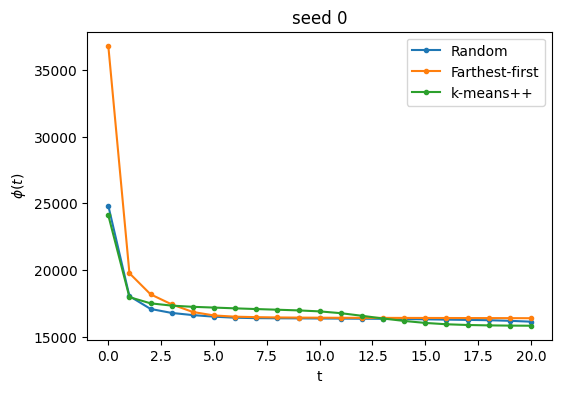

        method  median_phi0  min_phi20  median_phi20  max_phi20
        Random      26785.1    15811.1       15827.6    17143.4
Farthest-first      44623.0    15824.8       16373.4    16458.7
     k-means++      28192.5    15811.4       16157.3    17143.3
15811.08647802179


In [ ]:
inits = {'Random': init_random, 'Farthest-first': init_ff, 'k-means++': init_pp}
H = {name: np.array([kmeans(Z, f(Z, 4, s), 20)[2] for s in range(20)])
     for name, f in inits.items()}

plt.figure(figsize=(6,4))
for name in H:
    plt.plot(range(21), H[name][0], marker='o', ms=3, label=name)
plt.xlabel('t'); plt.ylabel(r'$\phi(t)$'); plt.title('seed 0'); plt.legend()
plt.show()

rows = []
for name in H:
    rows.append(dict(method=name,
                     median_phi0=np.median(H[name][:,0]),
                     min_phi20=H[name][:,20].min(),
                     median_phi20=np.median(H[name][:,20]),
                     max_phi20=H[name][:,20].max()))
print(pd.DataFrame(rows).round(1).to_string(index=False))

print(min(H[n][:,20].min() for n in H))

In [ ]:
_, idx = init_ff(Z, 4, 0, return_idx=True)
for r, i in enumerate(idx):
    top = np.argsort(-np.abs(Z[i]))[:3]
    tag = 'random start' if r == 0 else 'farthest-first'
    print(r+1, tag, d.loc[i, ['track_name','artists','track_genre']].tolist(),
          [(feats[j], round(Z[i][j], 1)) for j in top])

1 random start ['Wild World - 2009 Remastered Version', 'Mr. Big', 'metal'] [('tempo', np.float64(0.8)), ('valence', np.float64(0.8)), ('liveness', np.float64(0.8))]
2 farthest-first ['Sri Venkatesa Suprabhatam', 'M. S. Subbulakshmi;T. K. Murthy;V.V.Subramaniam', 'classical'] [('speechiness', np.float64(9.7)), ('valence', np.float64(1.7)), ('acousticness', np.float64(1.4))]
3 farthest-first ['Glassworks: Opening', 'Philip Glass;Víkingur Ólafsson', 'classical'] [('loudness', np.float64(-4.2)), ('tempo', np.float64(3.1)), ('danceability', np.float64(-2.6))]
4 farthest-first ['What a Karavaad', 'Anirudh Ravichander;Dhanush', 'hip-hop'] [('speechiness', np.float64(5.0)), ('liveness', np.float64(4.7)), ('tempo', np.float64(-1.5))]


In [ ]:
res = {}
for k in range(2, 9):
    best = None
    for s in range(10):
        out = kmeans(Z, init_pp(Z, k, s), 20)
        if best is None or out[2][-1] < best[2][-1]:
            best = out
    lab, C, h = best
    res[k] = dict(sse=h[-1],
                  sil=silhouette_score(Z, lab),
                  ari=adjusted_rand_score(d.track_genre, lab),
                  lab=lab)

print(pd.DataFrame({k: {m: v[m] for m in ['sse','sil','ari']}
                    for k, v in res.items()}).T.round(4))

          sse     sil     ari
2  21055.3956  0.3648  0.1981
3  17911.7142  0.2020  0.3507
4  15811.3890  0.2087  0.4699
5  14417.3969  0.2103  0.3324
6  13033.2194  0.2142  0.3472
7  12280.0399  0.1988  0.2968
8  11556.8300  0.1858  0.2454


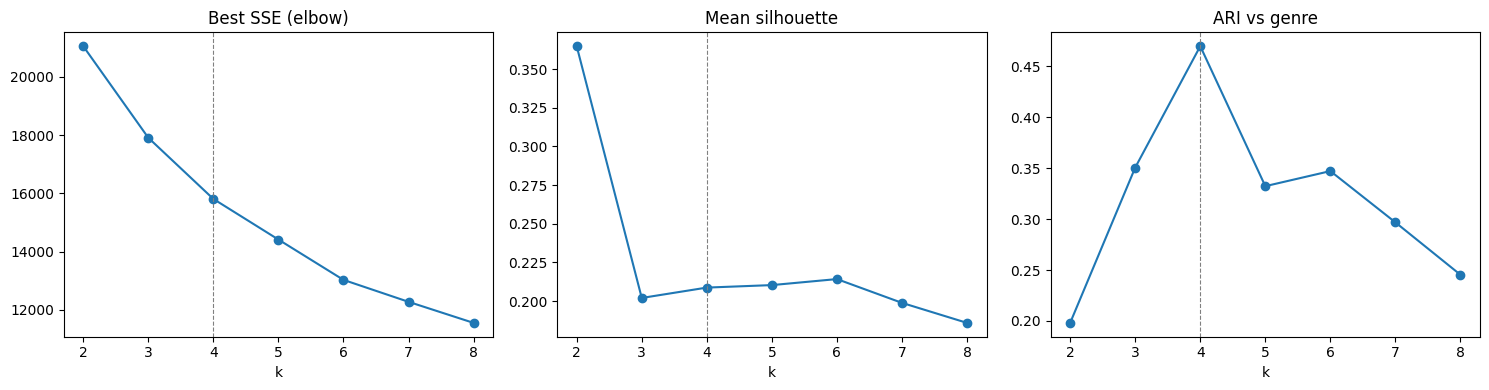

In [ ]:
ks = list(range(2, 9))
sse = [res[k]['sse'] for k in ks]
sil = [res[k]['sil'] for k in ks]
ari = [res[k]['ari'] for k in ks]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, y, name in zip(ax, [sse, sil, ari],
                      ['Best SSE (elbow)', 'Mean silhouette', 'ARI vs genre']):
    a.plot(ks, y, marker='o')
    a.set_xlabel('k'); a.set_title(name); a.set_xticks(ks)
    a.axvline(4, ls='--', c='gray', lw=0.8)
plt.tight_layout(); plt.show()

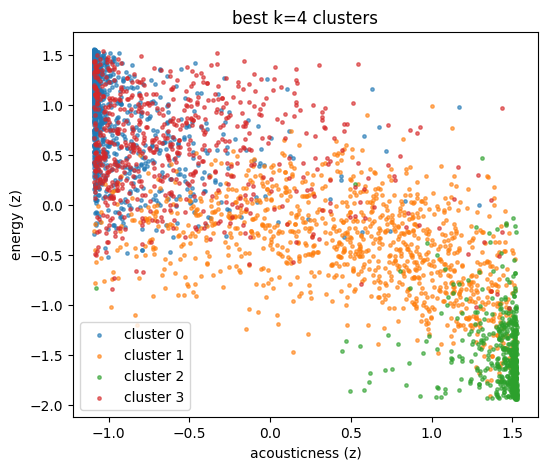

In [ ]:
lab4 = res[4]['lab']
plt.figure(figsize=(6, 5))
for c in range(4):
    m = lab4 == c
    plt.scatter(Z[m, ai], Z[m, ei], s=6, alpha=.6, label=f'cluster {c}')
plt.xlabel('acousticness (z)'); plt.ylabel('energy (z)'); plt.legend()
plt.title('best k=4 clusters'); plt.show()

In [ ]:
rng = np.random.default_rng(0)
null_sse = np.zeros((10, 7))
for r in range(10):
    Zn = np.column_stack([rng.permutation(Z[:, j]) for j in range(9)])
    for i, k in enumerate(range(2, 9)):
        null_sse[r, i] = min(kmeans(Zn, init_pp(Zn, k, s), 20)[2][-1] for s in range(10))

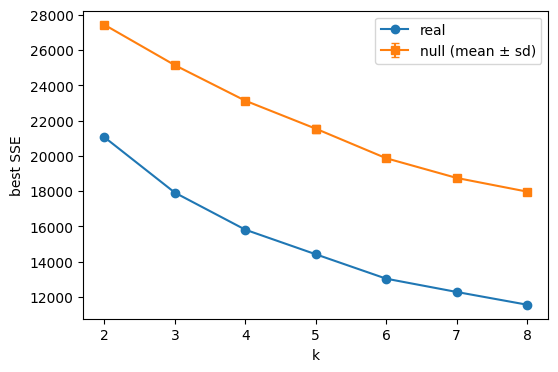

 k    real  null_mean  null_sd    gap  real/null
 2 21055.0    27432.0      3.4 6377.0      0.768
 3 17912.0    25141.0    143.6 7229.0      0.712
 4 15811.0    23127.0    144.2 7315.0      0.684
 5 14417.0    21539.0    220.8 7122.0      0.669
 6 13033.0    19863.0    137.4 6830.0      0.656
 7 12280.0    18746.0     48.9 6466.0      0.655
 8 11557.0    17970.0     40.1 6413.0      0.643
col_0          0    1    2    3
track_genre                    
classical     18  178  595   23
hip-hop       99  119    0  529
mandopop     190  722    0   73
metal        755   46    0   61


In [ ]:
m, s = null_sse.mean(0), null_sse.std(0)
plt.figure(figsize=(6, 4))
plt.plot(ks, sse, marker='o', label='real')
plt.errorbar(ks, m, yerr=s, marker='s', capsize=3, label='null (mean ± sd)')
plt.xlabel('k'); plt.ylabel('best SSE'); plt.legend(); plt.show()

gap = m - np.array(sse)
print(pd.DataFrame({'k': ks, 'real': np.round(sse,0), 'null_mean': np.round(m,0),
                    'null_sd': np.round(s,1), 'gap': np.round(gap,0),
                    'real/null': np.round(np.array(sse)/m,3)}).to_string(index=False))

print(pd.crosstab(d.track_genre, res[4]['lab']))